In [ ]:
# Sel 1
!pip install wfdb -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 8.0 MB/s eta 0:00:00


In [ ]:
# Sel 2 — lewati kalau Drive sudah ter-mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#untuk liatin berkas
import os
p = '/content/drive/MyDrive/Dataset/MODELS_V3/'
for f in sorted(os.listdir(p)):
    print(f, f"{os.path.getsize(p+f)/1e6:.2f} MB")

cdae_seed42_best.keras 1.09 MB
cdae_seed42_history.json 0.01 MB
lstm_seed42_best.keras 1.22 MB
lstm_seed42_history.json 0.01 MB


In [ ]:
# Sel 3 — prapemrosesan, ±15 menit
%run prapemrosesan_final.py
sets = run(CONFIG)

Definisi dimuat. Jalankan: sets = run(CONFIG)
1. BANK NOISE
  bw: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  ma: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  em: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)

2. PEMBACAAN REKAMAN
75 rekaman terpilih

  [1/75] I01  subjek=patient_01
  [2/75] I02  subjek=patient_01
  [3/75] I03  subjek=patient_02
  [4/75] I04  subjek=patient_02
  [5/75] I05  subjek=patient_02
  [6/75] I06  subjek=patient_03
  [7/75] I07  subjek=patient_03
  [8/75] I08  subjek=patient_04
  [9/75] I09  subjek=patient_05
  [10/75] I10  subjek=patient_05
  [11/75] I11  subjek=patient_05
  [12/75] I12  subjek=patient_06
  [13/75] I13  subjek=patient_06
  [14/75] I14  subjek=patient_06
  [15/75] I15  subjek=patient_07
  [16/75] I16  subjek=patient_08
  [17/75] I17  subjek=patient_08
  [18/75] I18  subjek=patient_09
  [19/75] I19  subjek=patient_09
  [20/75] I20  subjek=patient_10
  [21/75] I21  subjek=patient_10
  [22/75] I22  subjek=patie

In [ ]:
# Sel 4 — latih CDAE, ±7 menit
%run pelatihan_model.py
hist = train('cdae', seed=42)

model               parameter
CDAE_AE                86,092
LSTM_AE                94,668
ATTENTION_AE           78,476
PELATIHAN CDAE  (seed 42)
  train (42430, 512, 12) | val (10834, 512, 12)
  parameter: 86,092
Epoch 1/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 179s 265ms/step - loss: 0.0036 - mae: 0.0379 - val_loss: 0.0051 - val_mae: 0.0485 - learning_rate: 0.0010
Epoch 2/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 212s 280ms/step - loss: 0.0022 - mae: 0.0318 - val_loss: 0.0049 - val_mae: 0.0478 - learning_rate: 0.0010
Epoch 3/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 180s 271ms/step - loss: 0.0020 - mae: 0.0304 - val_loss: 0.0049 - val_mae: 0.0475 - learning_rate: 0.0010
Epoch 4/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 179s 270ms/step - loss: 0.0019 - mae: 0.0296 - val_loss: 0.0048 - val_mae: 0.0473 - learning_rate: 0.0010
Epoch 5/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 196s 261ms/step - loss: 0.0018 - mae: 0.0291 - val_loss: 0.0048 - val_mae: 0.0471 - learning_rate: 0.0010
Epoch 6/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 204s 264ms

In [ ]:
# Sel 5 — evaluasi per lead dalam mV, sekaligus per subjek
import numpy as np, tensorflow as tf
D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
M = '/content/drive/MyDrive/Dataset/MODELS_V3/cdae_seed42_best.keras'
Xn, Xc = np.load(D+"X_test_noisy.npy"), np.load(D+"X_test_clean.npy")
sc = np.load(D+"scale_test.npy").reshape(-1,1,1)
pvc, subj = np.load(D+"pvc_test.npy"), np.load(D+"subject_test.npy")
pred = tf.keras.models.load_model(M).predict(Xn, batch_size=128, verbose=1)
Xn, Xc, pred = Xn*sc, Xc*sc, pred*sc

names = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
def turun(m):
    a = np.mean((Xn[m]-Xc[m])**2, axis=(0,1)); b = np.mean((pred[m]-Xc[m])**2, axis=(0,1))
    return a, b, 100*(1-b/a)
a, b, t_all = turun(np.ones(len(Xn), bool))
_, _, t_pvc = turun(pvc); _, _, t_non = turun(~pvc)
print(f"{'lead':5s} {'MSE noisy':>11s} {'MSE CDAE':>11s} {'semua':>7s} {'PVC':>7s} {'nonPVC':>7s}")
for i, n_ in enumerate(names):
    print(f"{n_:5s} {a[i]:11.6f} {b[i]:11.6f} {t_all[i]:6.1f}% {t_pvc[i]:6.1f}% {t_non[i]:6.1f}%")

print(f"\n{'subjek':12s} {'n':>6s} {'V3':>8s} {'V4':>8s} {'V6':>8s}")
for s in np.unique(subj):
    m = subj == s
    _, _, t = turun(m)
    print(f"{s:12s} {m.sum():6d} {t[8]:7.1f}% {t[9]:7.1f}% {t[11]:7.1f}%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 16s 141ms/step
lead    MSE noisy    MSE CDAE   semua     PVC  nonPVC
I        0.057613    0.006837   88.1%   90.4%   86.0%
II       0.057165    0.017999   68.5%   79.0%   59.3%
III      0.057456    0.018126   68.5%   77.3%   60.8%
aVR      0.043239    0.007883   81.8%   87.2%   76.9%
aVL      0.043450    0.007992   81.6%   85.4%   78.1%
aVF      0.043115    0.016386   62.0%   74.0%   51.1%
V1       0.038774    0.009608   75.2%   76.8%   73.7%
V2       0.038951    0.012602   67.6%   71.7%   63.7%
V3       0.039026    0.021411   45.1%   42.0%   47.7%
V4       0.038898    0.017192   55.8%   73.9%   39.6%
V5       0.038956    0.014188   63.6%   69.7%   58.0%
V6       0.039016    0.023052   40.9%   45.0%   37.4%

subjek            n       V3       V4       V6
patient_09     1806     4.8%    54.0%    67.8%
patient_10     2709    67.6%    85.5%    86.6%
patient_16     2709    34.7%    76.0%    30.9%
patient_18     1806    26.2%    50.0%    24.1%
patient_25     180

In [ ]:
# # hapus setelah digunakan
# import numpy as np, tensorflow as tf

# D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
# M = '/content/drive/MyDrive/Dataset/MODELS_V3/cdae_seed42_best.keras'

# Xn = np.load(D+"X_test_noisy.npy"); Xc = np.load(D+"X_test_clean.npy")
# sc = np.load(D+"scale_test.npy").reshape(-1,1,1)
# subj = np.load(D+"subject_test.npy")
# pred = tf.keras.models.load_model(M).predict(Xn, batch_size=128, verbose=1)
# Xn, Xc, pred = Xn*sc, Xc*sc, pred*sc          # ke mV
# names = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

# # --- A. daya sinyal bersih per subjek (mV RMS) ---
# print("RMS sinyal bersih per subjek:")
# print(f"{'subjek':12s} {'V3':>8s} {'V4':>8s} {'V6':>8s} {'rata2':>8s}")
# for s in np.unique(subj):
#     r = np.sqrt(np.mean(Xc[subj==s]**2, axis=(0,1)))
#     print(f"{s:12s} {r[8]:8.4f} {r[9]:8.4f} {r[11]:8.4f} {r.mean():8.4f}")

# # --- B. SNR improvement per lead (dB) ---
# def snr_db(ref, sig):
#     r = ref - ref.mean(axis=1, keepdims=True)
#     e = sig - ref; e = e - e.mean(axis=1, keepdims=True)
#     return 10*np.log10(np.mean(r**2, axis=1) / np.mean(e**2, axis=1))

# imp = (snr_db(Xc, pred) - snr_db(Xc, Xn))
# print(f"\n{'lead':5s} {'SNRimp semua':>13s} {'tanpa p25':>11s}")
# keep = subj != 'patient_25'
# for i, n_ in enumerate(names):
#     print(f"{n_:5s} {imp[:,i].mean():12.2f} {imp[keep,i].mean():11.2f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 146ms/step
RMS sinyal bersih per subjek:
subjek             V3       V4       V6    rata2
patient_09     0.4099   0.2640   0.3406   0.3028
patient_10     0.2736   0.1865   0.2703   0.2309
patient_16     0.7415   0.5112   1.1255   0.5506
patient_18     0.2509   0.2440   0.2547   0.1648
patient_25     0.1214   0.5611   0.1791   0.1734
patient_30     0.2130   0.1848   0.2782   0.2129
patient_31     0.5303   0.4253   0.6531   0.4979


/tmp/ipykernel_2113/3054844272.py:25: RuntimeWarning: divide by zero encountered in log10
  return 10*np.log10(np.mean(r**2, axis=1) / np.mean(e**2, axis=1))



lead   SNRimp semua   tanpa p25
I            10.33       10.72
II            6.51        6.73
III           6.65        6.83
aVR           8.57        8.89
aVL           8.75        9.00
aVF           5.93        6.10
V1            7.58        7.73
V2            5.71        5.56
V3            4.50        4.46
V4             nan        6.32
V5            5.80        5.93
V6            4.95        4.94


/tmp/ipykernel_2113/3054844272.py:27: RuntimeWarning: invalid value encountered in subtract
  imp = (snr_db(Xc, pred) - snr_db(Xc, Xn))


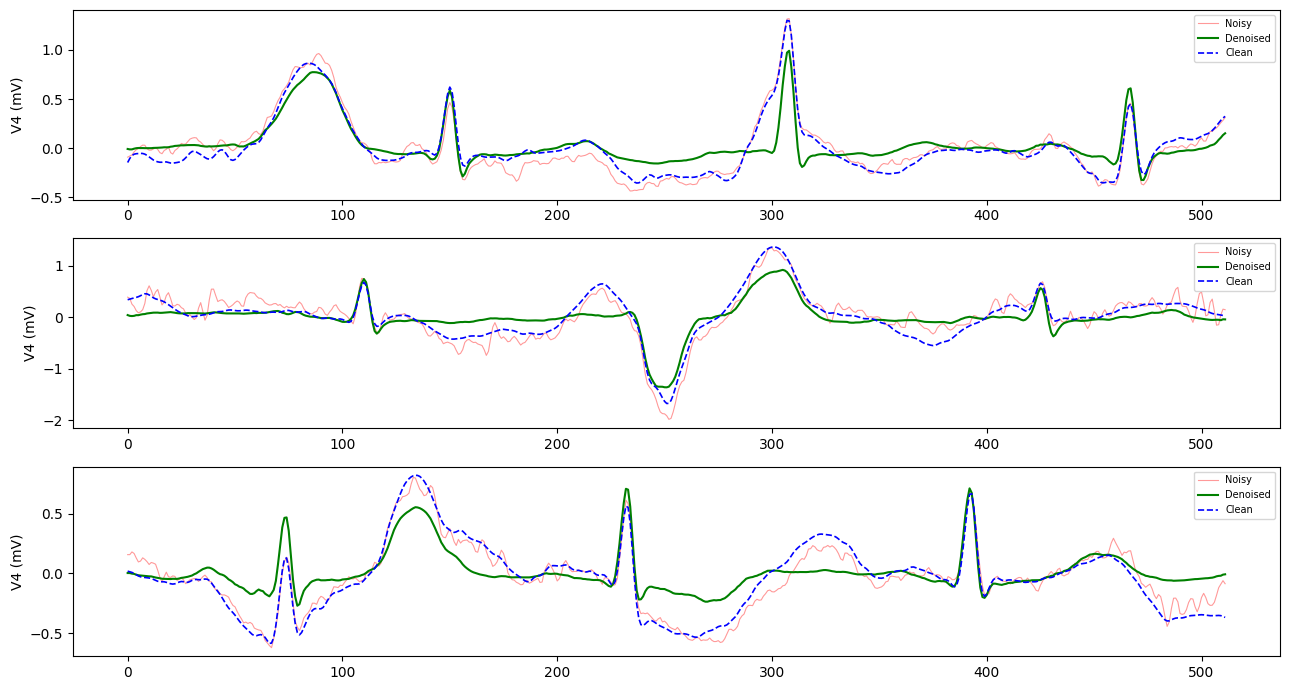

In [ ]:
# #hapus setelah digunakan
# import matplotlib.pyplot as plt
# idx = np.where(subj == 'patient_25')[0][:3]
# fig, ax = plt.subplots(3, 1, figsize=(13, 7))
# for a, i in zip(ax, idx):
#     a.plot(Xn[i,:,9], color='red', alpha=.4, lw=.8, label='Noisy')
#     a.plot(pred[i,:,9], color='green', lw=1.5, label='Denoised')
#     a.plot(Xc[i,:,9], color='blue', ls='--', lw=1.2, label='Clean')
#     a.set_ylabel('V4 (mV)'); a.legend(fontsize=7)
# plt.tight_layout(); plt.show()

In [ ]:
# # --- A. berapa segmen dengan lead konstan ---
# var = Xc.var(axis=1)                      # (N, 12)
# deg = var < 1e-12
# print(f"Total segmen dengan minimal satu lead konstan: {deg.any(axis=1).sum()}\n")
# for i, n_ in enumerate(names):
#     if deg[:, i].any():
#         print(f"  {n_}: {deg[:, i].sum()} segmen")
#         for s in np.unique(subj[deg[:, i]]):
#             print(f"      {s}: {(deg[:, i] & (subj == s)).sum()}")

# # --- B. SNRimp versi pooled (tahan terhadap segmen berdaya kecil) ---
# def pooled(ref, sig):
#     r = ref - ref.mean(axis=1, keepdims=True)
#     e = sig - ref; e = e - e.mean(axis=1, keepdims=True)
#     return 10*np.log10((r**2).sum(axis=(0,1)) / (e**2).sum(axis=(0,1)))

# ok = ~deg.any(axis=1)
# k  = ok & (subj != 'patient_25')
# a = pooled(Xc[ok], pred[ok]) - pooled(Xc[ok], Xn[ok])
# b = pooled(Xc[k],  pred[k])  - pooled(Xc[k],  Xn[k])
# print(f"\n{'lead':5s} {'SNRimp semua':>13s} {'tanpa p25':>11s}")
# for i, n_ in enumerate(names):
#     print(f"{n_:5s} {a[i]:13.2f} {b[i]:11.2f}")

# # --- C. proporsi amplitudo tiap lead terhadap rata-rata, per subjek ---
# print(f"\nRasio RMS lead terhadap rata-rata 12 lead:")
# print(f"{'subjek':12s} {'V3':>7s} {'V4':>7s} {'V6':>7s} {'maks':>7s} {'lead':>6s}")
# for s in np.unique(subj):
#     r = np.sqrt(np.mean(Xc[subj==s]**2, axis=(0,1))); q = r / r.mean()
#     print(f"{s:12s} {q[8]:7.2f} {q[9]:7.2f} {q[11]:7.2f} {q.max():7.2f} {names[q.argmax()]:>6s}")

Total segmen dengan minimal satu lead konstan: 1084

  V4: 1084 segmen
      patient_25: 1084

lead   SNRimp semua   tanpa p25
I              9.45        9.53
II             5.66        5.70
III            5.62        5.63
aVR            7.85        7.91
aVL            7.76        7.78
aVF            4.87        4.89
V1             6.32        6.34
V2             5.13        5.13
V3             3.09        3.08
V4             4.22        5.54
V5             4.65        4.80
V6             2.63        2.63

Rasio RMS lead terhadap rata-rata 12 lead:
subjek            V3      V4      V6    maks   lead
patient_09      1.35    0.87    1.12    1.76     V2
patient_10      1.18    0.81    1.17    1.45     II
patient_16      1.35    0.93    2.04    2.04     V6
patient_18      1.52    1.48    1.54    1.79     V5
patient_25      0.70    3.24    1.03    3.24     V4
patient_30      1.00    0.87    1.31    1.44     V1
patient_31      1.07    0.85    1.31    1.56     II


In [ ]:
# import numpy as np
# D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
# names = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

# for split in ("train", "val", "test"):
#     Xc_ = np.load(D+f"X_{split}_clean.npy", mmap_mode='r')
#     sj  = np.load(D+f"subject_{split}.npy")
#     deg = np.zeros((len(Xc_), 12), bool)
#     for i in range(0, len(Xc_), 2000):                     # dipotong agar hemat RAM
#         deg[i:i+2000] = np.asarray(Xc_[i:i+2000]).var(axis=1) < 1e-12
#     bad = deg.any(axis=1)
#     print(f"\n{split.upper()}: {bad.sum()} dari {len(bad):,} segmen ({100*bad.mean():.2f}%)")
#     for i, n_ in enumerate(names):
#         if deg[:, i].any():
#             who = {s: int((deg[:, i] & (sj == s)).sum()) for s in np.unique(sj[deg[:, i]])}
#             print(f"   {n_}: {deg[:, i].sum()} segmen  {who}")

# # nilai konstannya berapa? (nol atau saturasi)
# Xc = np.load(D+"X_test_clean.npy", mmap_mode='r')
# sj = np.load(D+"subject_test.npy")
# i25 = np.where(sj == 'patient_25')[0]
# v4 = np.asarray(Xc[i25][:, :, 9])
# flat = v4.var(axis=1) < 1e-12
# print("\nNilai V4 saat konstan:", np.unique(v4[flat][:, 0])[:5], "...")


TRAIN: 895 dari 42,430 segmen (2.11%)
   V3: 895 segmen  {np.str_('patient_02'): 895}

VAL: 877 dari 10,834 segmen (8.09%)
   V6: 877 segmen  {np.str_('patient_01'): 877}

TEST: 1085 dari 14,448 segmen (7.51%)
   V4: 1085 segmen  {np.str_('patient_25'): 1085}

Nilai V4 saat konstan: [-2.5979214e-06 -1.0220581e-06 -1.7856730e-07 -6.1556158e-08
 -3.0929254e-08] ...


In [ ]:
# import numpy as np
# D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
# THRESH_MV = 1e-3        # 1 µV — jauh di bawah amplitudo lead terkecil sekalipun

# for split in ("train", "val", "test"):
#     Xc = np.load(D+f"X_{split}_clean.npy", mmap_mode='r')
#     sc = np.load(D+f"scale_{split}.npy")
#     keep = np.ones(len(Xc), bool)
#     for i in range(0, len(Xc), 2000):
#         blk = np.asarray(Xc[i:i+2000]) * sc[i:i+2000].reshape(-1, 1, 1)   # mV
#         rms = np.sqrt((blk**2).mean(axis=1))                              # (n, 12)
#         keep[i:i+2000] = (rms >= THRESH_MV).all(axis=1)
#     np.save(D+f"valid_{split}.npy", keep)
#     print(f"{split:5s}: buang {(~keep).sum():5,} -> sisa {keep.sum():6,} "
#           f"({100*keep.mean():.1f}%)")

train: buang   898 -> sisa 41,532 (97.9%)
val  : buang   880 -> sisa  9,954 (91.9%)
test : buang 1,121 -> sisa 13,327 (92.2%)


In [ ]:
# import tensorflow as tf
# names = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

# Xn = np.load(D+"X_test_noisy.npy"); Xc = np.load(D+"X_test_clean.npy")
# sc = np.load(D+"scale_test.npy").reshape(-1,1,1)
# keep = np.load(D+"valid_test.npy"); pvc = np.load(D+"pvc_test.npy")
# M = '/content/drive/MyDrive/Dataset/MODELS_V3/cdae_seed42_best.keras'
# pred = tf.keras.models.load_model(M).predict(Xn, batch_size=128, verbose=1)
# Xn, Xc, pred = Xn*sc, Xc*sc, pred*sc

# def pooled(ref, sig):
#     r = ref - ref.mean(axis=1, keepdims=True)
#     e = sig - ref; e = e - e.meaan(axis=1, keepdims=True)
#     return 10*np.log10((r**2).sum(axis=(0,1)) / (e**2).sum(axis=(0,1)))

# def baris(m):
#     return (pooled(Xc[m], pred[m]) - pooled(Xc[m], Xn[m]),
#             np.mean((Xn[m]-Xc[m])**2, axis=(0,1)),
#             np.mean((pred[m]-Xc[m])**2, axis=(0,1)))

# imp, mse_n, mse_p = baris(keep)
# imp_pvc, _, _ = baris(keep &  pvc)
# imp_non, _, _ = baris(keep & ~pvc)

# print(f"\n{'lead':5s} {'MSE noisy':>11s} {'MSE CDAE':>11s} {'SNRimp':>8s} "
#       f"{'PVC':>8s} {'nonPVC':>8s}")
# for i, n_ in enumerate(names):
#     print(f"{n_:5s} {mse_n[i]:11.6f} {mse_p[i]:11.6f} {imp[i]:7.2f} "
#           f"{imp_pvc[i]:7.2f} {imp_non[i]:7.2f}")
# print(f"\nRata-rata 12 lead: SNRimp {imp.mean():.2f} dB")

113/113 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step

lead    MSE noisy    MSE CDAE   SNRimp      PVC   nonPVC
I        0.062134    0.007280    9.46   10.32    8.80
II       0.061612    0.019322    5.66    7.03    4.72
III      0.061930    0.019451    5.62    6.67    4.87
aVR      0.046570    0.008437    7.85    9.13    6.94
aVL      0.046800    0.008544    7.76    8.55    7.15
aVF      0.046411    0.017605    4.87    6.11    3.97
V1       0.041759    0.010346    6.32    6.56    6.09
V2       0.041957    0.013609    5.13    5.74    4.60
V3       0.042028    0.023122    3.09    2.82    3.33
V4       0.041901    0.018304    4.23    6.12    3.00
V5       0.041959    0.015273    4.65    5.32    4.12
V6       0.042025    0.024813    2.63    3.02    2.30

Rata-rata 12 lead: SNRimp 5.61 dB


patient_25: 1806 segmen, rekaman [np.str_('I57'), np.str_('I58')]
V4 datar: 1123 (62%) | normal: 683


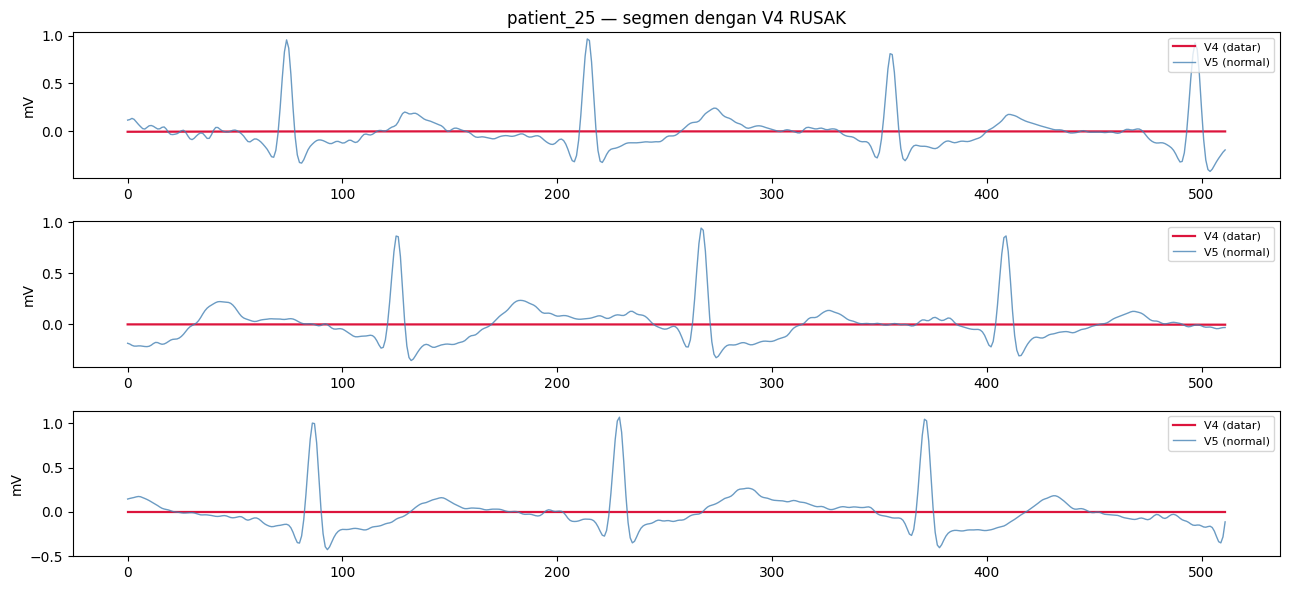

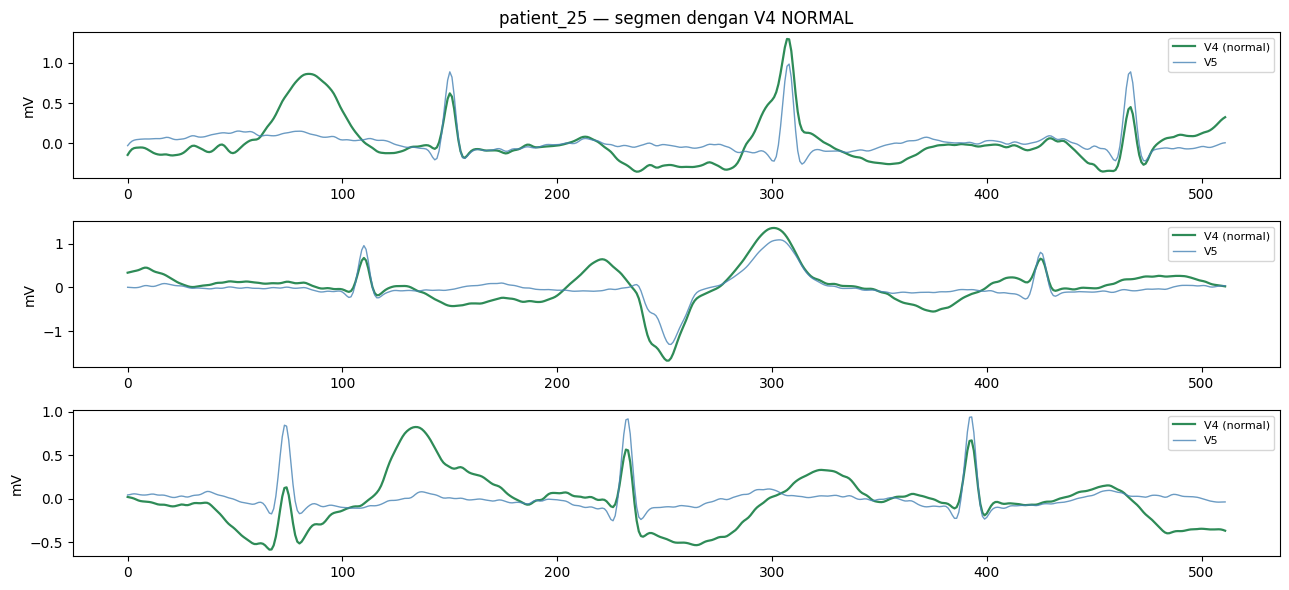

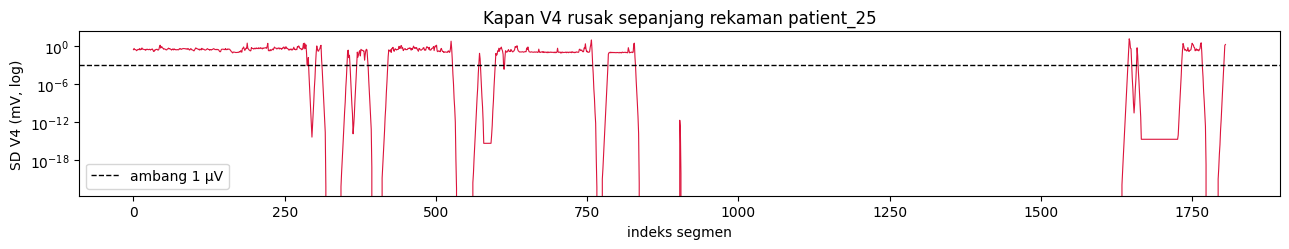

AttributeError: `ptp` was removed from the ndarray class in NumPy 2.0. Use np.ptp(arr, ...) instead.

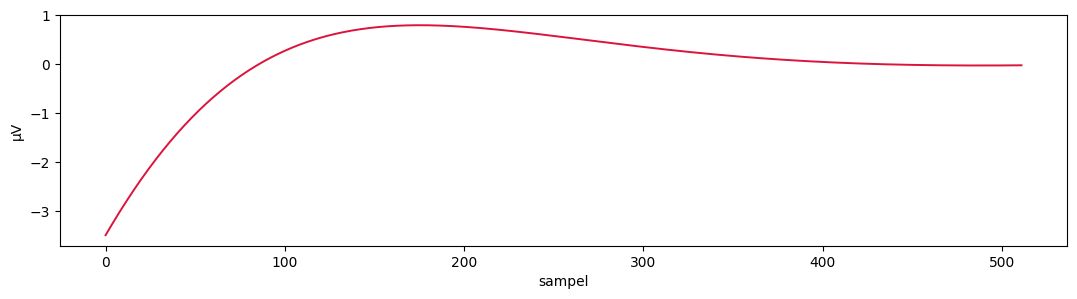

In [ ]:
# #potongan v4 yang datar
# import numpy as np, matplotlib.pyplot as plt

# D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
# Xc = np.load(D+"X_test_clean.npy", mmap_mode='r')
# sc = np.load(D+"scale_test.npy")
# subj = np.load(D+"subject_test.npy")
# rec  = np.load(D+"record_test.npy")

# i25 = np.where(subj == 'patient_25')[0]
# v4  = np.asarray(Xc[i25][:, :, 9]) * sc[i25].reshape(-1, 1)     # V4 dalam mV
# v5  = np.asarray(Xc[i25][:, :, 10]) * sc[i25].reshape(-1, 1)    # V5 pembanding
# flat = v4.std(axis=1) < 1e-3

# print(f"patient_25: {len(i25)} segmen, rekaman {sorted(set(rec[i25]))}")
# print(f"V4 datar: {flat.sum()} ({100*flat.mean():.0f}%) | normal: {(~flat).sum()}")

# # --- 1. tiga segmen V4 datar, dibandingkan V5 di segmen yang sama ---
# fig, ax = plt.subplots(3, 1, figsize=(13, 6))
# for a, i in zip(ax, np.where(flat)[0][:3]):
#     a.plot(v4[i], color='crimson', lw=1.6, label='V4 (datar)')
#     a.plot(v5[i], color='steelblue', lw=1.0, alpha=.8, label='V5 (normal)')
#     a.set_ylabel('mV'); a.legend(fontsize=8, loc='upper right')
# ax[0].set_title('patient_25 — segmen dengan V4 RUSAK')
# plt.tight_layout(); plt.show()

# # --- 2. tiga segmen V4 normal ---
# fig, ax = plt.subplots(3, 1, figsize=(13, 6))
# for a, i in zip(ax, np.where(~flat)[0][:3]):
#     a.plot(v4[i], color='seagreen', lw=1.6, label='V4 (normal)')
#     a.plot(v5[i], color='steelblue', lw=1.0, alpha=.8, label='V5')
#     a.set_ylabel('mV'); a.legend(fontsize=8, loc='upper right')
# ax[0].set_title('patient_25 — segmen dengan V4 NORMAL')
# plt.tight_layout(); plt.show()

# # --- 3. peta kerusakan sepanjang rekaman ---
# plt.figure(figsize=(13, 2.6))
# plt.plot(v4.std(axis=1), lw=.8, color='crimson')
# plt.axhline(1e-3, ls='--', color='k', lw=1, label='ambang 1 µV')
# plt.yscale('log'); plt.xlabel('indeks segmen'); plt.ylabel('SD V4 (mV, log)')
# plt.title('Kapan V4 rusak sepanjang rekaman patient_25')
# plt.legend(); plt.tight_layout(); plt.show()

# # --- 4. zoom satu segmen datar, skala diperbesar ---
# i = np.where(flat)[0][0]
# plt.figure(figsize=(13, 3))
# plt.plot(v4[i] * 1000, color='crimson', lw=1.4)
# plt.ylabel('µV'); plt.xlabel('sampel')
# plt.title(f'Zoom V4 datar — rentang hanya {1000*v4[i].ptp():.3f} µV')
# plt.tight_layout(); plt.show()

In [ ]:
%run pelatihan_model.py
hist_lstm = train('lstm', seed=42)

model               parameter
CDAE_AE                86,092
LSTM_AE                94,668
ATTENTION_AE           78,476
PELATIHAN LSTM  (seed 42)
  train (42430, 512, 12) | val (10834, 512, 12)
  parameter: 94,668
Epoch 1/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 31s 36ms/step - loss: 0.0041 - mae: 0.0381 - val_loss: 0.0051 - val_mae: 0.0472 - learning_rate: 0.0010
Epoch 2/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - loss: 0.0021 - mae: 0.0300 - val_loss: 0.0047 - val_mae: 0.0453 - learning_rate: 0.0010
Epoch 3/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - loss: 0.0018 - mae: 0.0281 - val_loss: 0.0046 - val_mae: 0.0447 - learning_rate: 0.0010
Epoch 4/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - loss: 0.0017 - mae: 0.0270 - val_loss: 0.0045 - val_mae: 0.0444 - learning_rate: 0.0010
Epoch 5/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - loss: 0.0016 - mae: 0.0261 - val_loss: 0.0045 - val_mae: 0.0444 - learning_rate: 0.0010
Epoch 6/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - loss

In [ ]:
%run pelatihan_model.py
hist_attn = train('attention', seed=42)

model               parameter
CDAE_AE                86,092
LSTM_AE                94,668
ATTENTION_AE           78,476
PELATIHAN ATTENTION  (seed 42)
  train (42430, 512, 12) | val (10834, 512, 12)
  parameter: 78,476
Epoch 1/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 40s 35ms/step - loss: 0.0098 - mae: 0.0552 - val_loss: 0.0063 - val_mae: 0.0519 - learning_rate: 0.0010
Epoch 2/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0034 - mae: 0.0386 - val_loss: 0.0050 - val_mae: 0.0475 - learning_rate: 0.0010
Epoch 3/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0028 - mae: 0.0352 - val_loss: 0.0044 - val_mae: 0.0445 - learning_rate: 0.0010
Epoch 4/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0025 - mae: 0.0334 - val_loss: 0.0043 - val_mae: 0.0437 - learning_rate: 0.0010
Epoch 5/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0024 - mae: 0.0323 - val_loss: 0.0042 - val_mae: 0.0432 - learning_rate: 0.0010
Epoch 6/100
663/663 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0

In [ ]:
#Perbandingan
import numpy as np, tensorflow as tf, pandas as pd
from pelatihan_model import PositionalEncoding

D = '/content/drive/MyDrive/Dataset/PROCESSED_V3/'
MD = '/content/drive/MyDrive/Dataset/MODELS_V3/'
names = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

Xn0 = np.load(D+"X_test_noisy.npy"); Xc0 = np.load(D+"X_test_clean.npy")
sc = np.load(D+"scale_test.npy").reshape(-1,1,1)
keep = np.load(D+"valid_test.npy"); pvc = np.load(D+"pvc_test.npy")
Xn, Xc = Xn0*sc, Xc0*sc

def pooled(ref, sig):
    r = ref - ref.mean(axis=1, keepdims=True)
    e = sig - ref; e = e - e.mean(axis=1, keepdims=True)
    return 10*np.log10((r**2).sum(axis=(0,1)) / (e**2).sum(axis=(0,1)))

rows = []
for core in ("cdae", "lstm", "attention"):
    m = tf.keras.models.load_model(MD+f"{core}_seed42_best.keras",
            custom_objects={'PositionalEncoding': PositionalEncoding})
    pr = m.predict(Xn0, batch_size=128, verbose=0)*sc
    imp     = pooled(Xc[keep], pr[keep]) - pooled(Xc[keep], Xn[keep])
    imp_pvc = pooled(Xc[keep&pvc], pr[keep&pvc]) - pooled(Xc[keep&pvc], Xn[keep&pvc])
    mse     = np.mean((pr[keep]-Xc[keep])**2, axis=(0,1))
    rows.append(dict(model=core, params=m.count_params(), snrimp=imp.mean(),
                     snrimp_pvc=imp_pvc.mean(), mse=mse.mean(),
                     **{f"snrimp_{n}": imp[i] for i, n in enumerate(names)}))
    print(f"{core:10s} SNRimp {imp.mean():5.2f} dB | PVC {imp_pvc.mean():5.2f} dB | MSE {mse.mean():.6f}")

df = pd.DataFrame(rows)
df.to_csv(MD+"perbandingan_3model.csv", index=False)
print("\n", df[['model','params','snrimp','snrimp_pvc','mse']].round(4).to_string(index=False))
print("\nSNRimp per lead (dB):")
print(df.set_index('model')[[f"snrimp_{n}" for n in names]].round(2).T.to_string())

cdae       SNRimp  5.61 dB | PVC  6.45 dB | MSE 0.015512
lstm       SNRimp  5.70 dB | PVC  6.90 dB | MSE 0.013949
attention  SNRimp  6.83 dB | PVC  7.80 dB | MSE 0.010831

     model  params  snrimp  snrimp_pvc    mse
     cdae   86092  5.6055      6.4484 0.0155
     lstm   94668  5.7011      6.8958 0.0139
attention   78476  6.8266      7.8042 0.0108

SNRimp per lead (dB):
model       cdae  lstm  attention
snrimp_I    9.46  8.93      10.70
snrimp_II   5.66  5.39       6.66
snrimp_III  5.62  5.51       6.51
snrimp_aVR  7.85  7.39       9.02
snrimp_aVL  7.76  7.53       8.73
snrimp_aVF  4.87  4.74       5.79
snrimp_V1   6.32  5.92       7.13
snrimp_V2   5.13  5.69       6.49
snrimp_V3   3.09  4.45       5.04
snrimp_V4   4.22  4.09       5.71
snrimp_V5   4.65  5.02       5.18
snrimp_V6   2.63  3.76       4.95


In [ ]:
%run analisis_morfologi.py
hasil = jalankan()

Definisi dimuat. Jalankan: hasil = jalankan()
Denyut PVC yang dianalisis: 3,238 dari 13,327 segmen valid

RATA-RATA 12 LEAD (nilai err_* dan flip dalam %, makin kecil makin baik)
           flip_peak_index  korelasi_QRS  err_QRS_Int  err_Peak  err_Peak_inv  err_RMS    err_VAR
sumber                                                                                           
noisy                 9.04          0.96    28.170000     18.73     78.849998    14.29  14.930000
cdae                  7.36          0.94    16.959999     13.63     60.180000    11.28  21.059999
lstm                  5.64          0.96    18.350000     13.86     44.130001    13.66  25.809999
attention             8.44          0.96    17.379999     16.33     50.650002    11.14  19.590000 

FLIP RATE Peak_index PER LEAD (%)
     noisy  cdae  lstm  attention
I     35.4  28.5  16.0       38.7
II     3.4   1.6   1.2        1.3
III    6.0   1.4   2.0        2.3
aVR    8.3   3.3   2.3        2.2
aVL   22.7  23.3  24.5     

In [ ]:
#buat liat seimbang atau ga nya
import numpy as np, pandas as pd, tensorflow as tf
from pelatihan_model import PositionalEncoding
from analisis_morfologi import (CFG, LEADS, qrs_windows, potong,
                                f_peak_index, f_peak, f_rms, f_var, f_qrs_int)

D, MD = CFG["data_dir"], CFG["model_dir"]
Xn0 = np.load(D+"X_test_noisy.npy"); Xc0 = np.load(D+"X_test_clean.npy")
sc = np.load(D+"scale_test.npy").reshape(-1,1,1)
keep = np.load(D+"valid_test.npy")
rpk = np.load(D+"rpeak_test.npy", allow_pickle=True)
sym = np.load(D+"symbol_test.npy", allow_pickle=True)
Xn, Xc = Xn0*sc, Xc0*sc

seg, pos, wc = qrs_windows(Xc, rpk, sym, keep, CFG)
W = wc.shape[-1]
srcs = {"noisy": potong(Xn, seg, pos, W)}
for core in CFG["models"]:
    m = tf.keras.models.load_model(MD+f"{core}_seed42_best.keras",
            custom_objects={"PositionalEncoding": PositionalEncoding})
    srcs[core] = potong(m.predict(Xn0, batch_size=128, verbose=0)*sc, seg, pos, W)

# denyut yang rasionya jauh dari ambang 1,5 -> flip-nya bukan efek ambang
mx, mn = wc.max(-1), wc.min(-1)
ratio = np.abs(np.where(np.abs(mx) > np.abs(mn), mx/(mn-1e-12), mn/(mx+1e-12)))
stabil = (ratio < 1.2) | (ratio > 1.9)
pi_c = f_peak_index(wc)

rows = {}
for k, w in srcs.items():
    r = {}
    for nm, fn in [("QRS_Int", lambda x: f_qrs_int(x, CFG["fs"])), ("Peak", f_peak),
                   ("RMS", f_rms), ("VAR", f_var)]:
        c, t = fn(wc), fn(w)
        r["bias_"+nm] = float(np.mean(t-c)/(np.mean(np.abs(c))+1e-12)*100)
    fl = (f_peak_index(w) != pi_c)
    r["flip_semua"]  = float(fl.mean()*100)
    r["flip_stabil"] = float(fl[stabil].mean()*100)
    rows[k] = r

print(pd.DataFrame(rows).T.round(2).to_string())
print(f"\nBeat-lead dekat ambang 1,5: {100*(~stabil).mean():.1f}%")
print("\nProporsi dekat ambang per lead (%):")
print(pd.Series(100*(~stabil).mean(axis=0), index=LEADS).round(1).to_string())

           bias_QRS_Int  bias_Peak  bias_RMS  bias_VAR  flip_semua  flip_stabil
noisy              0.07       1.11      2.66      2.81        9.04         6.74
cdae               0.02      -0.89     -0.18     -8.60        7.36         4.83
lstm               1.96      -0.64      0.94     -2.99        5.64         3.18
attention         -0.38       1.45     -2.07     -3.20        8.44         5.58

Beat-lead dekat ambang 1,5: 5.4%

Proporsi dekat ambang per lead (%):
I      13.6
II      3.0
III     2.6
aVR     3.2
aVL    16.0
aVF     2.2
V1      0.4
V2      1.5
V3      6.4
V4      9.4
V5      6.3
V6      1.0


Definisi dimuat. Jalankan: hasil = jalankan()
Segmen valid: 13,327 | denyut PVC: 3,238
Denyut-lead dekat ambang (dibuang dari flip_stabil): 5.4%

Memuat bank noise (bagian uji)...
  bw: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  ma: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  em: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)

Memuat model...

=== SNR input +10 dB ===
  noisy      SNR terukur  9.02 dB | flip  3.09% | korelasi 0.985
  cdae       SNRimp  1.30 dB | flip  4.41% | korelasi 0.945
  lstm       SNRimp  1.42 dB | flip  2.81% | korelasi 0.960
  attention  SNRimp  2.83 dB | flip  5.60% | korelasi 0.965

=== SNR input +5 dB ===
  noisy      SNR terukur  4.02 dB | flip  6.89% | korelasi 0.960
  cdae       SNRimp  5.59 dB | flip  4.83% | korelasi 0.941
  lstm       SNRimp  5.73 dB | flip  3.17% | korelasi 0.956
  attention  SNRimp  6.85 dB | flip  5.61% | korelasi 0.959

=== SNR input +0 dB ===
  noisy      SNR terukur -0.98 dB | flip 14.43% | k

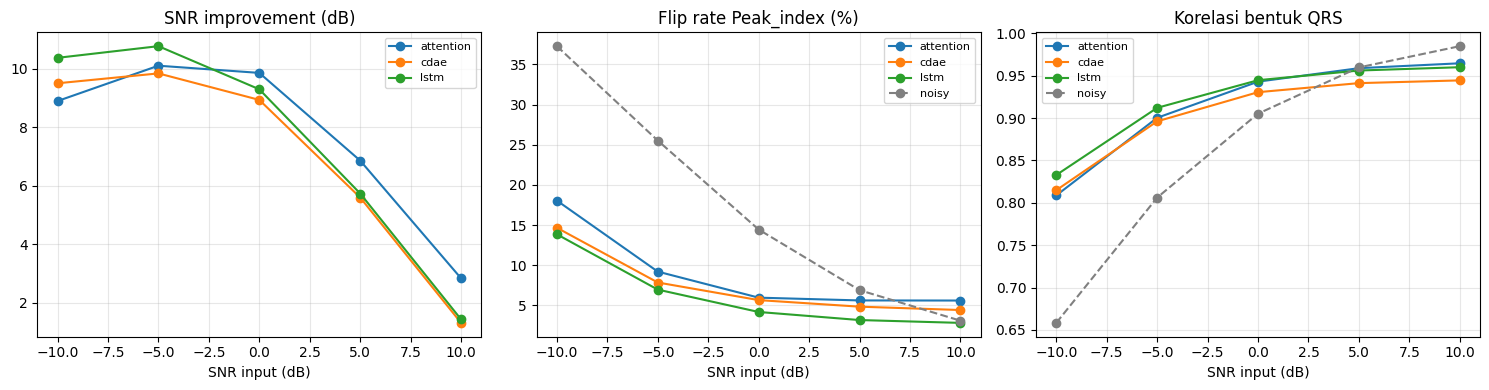

In [ ]:
%run stress_test.py
hasil = jalankan()
plot(hasil["ringkas"])

In [ ]:
%run uji_statistik.py
hasil = jalankan()

Definisi dimuat. Jalankan: hasil = jalankan()
Segmen valid: 13,327 | denyut PVC: 3,238
Denyut-lead dekat ambang (dibuang dari flip_stabil): 5.4%

Subjek uji: 6 | denyut PVC: 3,238

  bw: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  ma: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
  em: 464,028 sampel @ 257 Hz  (train 324,819 / test 139,209)
=== SNR input +10 dB ===
=== SNR input +5 dB ===
=== SNR input +0 dB ===
=== SNR input -5 dB ===
=== SNR input -10 dB ===

FLIP RATE Peak_index  (selisih = A - B, poin persen; negatif = A lebih baik)
 +10 dB  lstm      vs attention | selisih  -2.78 pp | denyut p=9.0e-158 *** | subjek 3/6 p=1.000 ns
 +10 dB  lstm      vs cdae      | selisih  -1.60 pp | denyut p=3.5e-58 *** | subjek 4/6 p=1.000 ns
 +10 dB  attention vs cdae      | selisih  +1.18 pp | denyut p=1.8e-32 *** | subjek 1/6 p=1.000 ns
 +10 dB  lstm      vs noisy     | selisih  -0.27 pp | denyut p=9.1e-03 **  | subjek 3/6 p=1.000 ns
 +10 dB  attention vs noisy     | se

<Figure size 640x480 with 0 Axes>